# Drug Molecule Generation with Machine Learning (v1.0)
**Pre-training on ZINC250K → Safety Fine-Tuning on Tox21 → F1 Version Evaluation**

### Pipeline Stages
1. **Data Gather** — Fetch & cache ZINC250K and Tox21 datasets
2. **Data Processing (ZINC250K)** — RDKit canonicalization, atom-wise SMILES tokenization, Train/Val/Test splits
3. **Training the Model (ZINC250K)** — Pre-train `SMILESGeneratorGRU` on ZINC250K drug-like molecules
4. **Evaluate (ZINC250K)** — Next-token metrics + de novo validity, uniqueness, novelty, QED & Lipinski evaluation
5. **Extract File of the Model (ZINC250K)** — Export `models/zinc250k_pretrained_v1.pt`
6. **Data Processing (Tox21)** — Clean 12-assay Tox21 toxicity data, build Tox21 Safety Evaluator, prepare safe drug-like subset
7. **Fine-Tune (Tox21)** — KL-regularized fine-tuning on verified non-toxic drug-like Tox21 molecules
8. **Evaluate (Tox21)** — Evaluate Tox21 test performance & generated molecule safety/drug-likeness
9. **Extract File of the Model (Tox21)** — Export `models/tox21_finetuned_v1.pt`
10. **Evaluate Using F1 Score** — Compare extracted model versions via **Safe-Drug Generation F1** & **Token F1** and record best version in `metrics/version_leaderboard.json`


In [1]:
import gzip
import json
import math
import os
import random
import re
import time
import urllib.request
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from datasets import load_dataset
from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import Crippen, Descriptors, Lipinski, QED, rdFingerprintGenerator
from rdkit.Chem.Scaffolds import MurckoScaffold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset

# Silence verbose RDKit parse warnings during validity checks
RDLogger.DisableLog("rdApp.*")

VERSION_TAG = "v1.0"
SEED = 42

def seed_everything(seed: int = 42) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cpu":
    torch.set_num_threads(min(12, os.cpu_count() or 4))
USE_AMP = DEVICE.type == "cuda"
AMP_DTYPE = torch.bfloat16 if (USE_AMP and torch.cuda.is_bf16_supported()) else torch.float16

DATA_DIR = Path("data")
MODELS_DIR = Path("models")
METRICS_DIR = Path("metrics")
for d in (DATA_DIR, MODELS_DIR, METRICS_DIR):
    d.mkdir(parents=True, exist_ok=True)

print(f"Version       : {VERSION_TAG}")
print(f"PyTorch       : {torch.__version__}")
print(f"Device        : {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else ""))
print(f"Mixed Prec.   : {USE_AMP} ({AMP_DTYPE})")


/home/mingoll/Projects/Mine/Molecule_Generation/.venv/lib/python3.15/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Version       : v1.0
PyTorch       : 2.15.0+cpu
Device        : cpu
Mixed Prec.   : False (torch.float16)


---
## 1. Data Gather
Load **ZINC250K** via Hugging Face `datasets` (`load_dataset("yairschiff/zinc250k")`) and download **Tox21** (`tox21.csv.gz`) into `data/` with local caching.


In [2]:
# Load ZINC250K from Hugging Face Hub (cached locally in data/hf_cache)
HF_CACHE_DIR = DATA_DIR / "hf_cache"
HF_CACHE_DIR.mkdir(parents=True, exist_ok=True)

ds = load_dataset("yairschiff/zinc250k", cache_dir=str(HF_CACHE_DIR))
print("Loaded Hugging Face dataset yairschiff/zinc250k:")
print(ds)

zinc_train_raw_df = ds["train"].to_pandas()
zinc_eval_raw_df = ds["validation"].to_pandas()

TOX21_URLS = [
    "https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/tox21.csv.gz",
]
TOX21_PATH = DATA_DIR / "tox21.csv.gz"

def download_with_fallback(urls: list[str], dest: Path, min_bytes: int = 10_000) -> Path:
    if dest.exists() and dest.stat().st_size >= min_bytes:
        print(f"[Cached] {dest} ({dest.stat().st_size / (1024 * 1024):.2f} MB)")
        return dest
    last_err = None
    for url in urls:
        try:
            print(f"Downloading {url} -> {dest} ...")
            req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req, timeout=60) as resp, open(dest, "wb") as out:
                out.write(resp.read())
            if dest.stat().st_size >= min_bytes:
                print(f"[Downloaded] {dest} ({dest.stat().st_size / (1024 * 1024):.2f} MB)")
                return dest
        except Exception as exc:
            last_err = exc
            print(f"Mirror failed ({url}): {exc}")
    raise RuntimeError(f"Failed to download {dest} from all mirrors. Last error: {last_err}")

download_with_fallback(TOX21_URLS, TOX21_PATH, min_bytes=50_000)
tox21_raw_df = pd.read_csv(TOX21_PATH, compression="gzip")

print(f"ZINC250K train shape : {zinc_train_raw_df.shape} | val shape: {zinc_eval_raw_df.shape}")
print(f"Tox21 shape          : {tox21_raw_df.shape} | columns: {list(tox21_raw_df.columns)}")
display(zinc_train_raw_df[["smiles", "canonical_smiles", "logP", "qed", "SAS"]].head(3))
display(tox21_raw_df.head(3))


Using the latest cached version of the dataset since yairschiff/zinc250k couldn't be found on the Hugging Face Hub (offline mode is enabled).


Found the latest cached dataset configuration 'default' at data/hf_cache/yairschiff___zinc250k/default/0.0.0/c6e5785ff798797d818d1ae354ccbd54c10e5634 (last modified on Wed Nov 25 14:53:56 2026).


Loaded Hugging Face dataset yairschiff/zinc250k:
DatasetDict({
    train: Dataset({
        features: ['smiles', 'logP', 'qed', 'SAS', 'canonical_smiles', 'single_bond', 'double_bond', 'triple_bond', 'aromatic_bond', 'ring_count', 'R3', 'R4', 'R5', 'R6', 'R7', 'R8', 'R9', 'R10', 'R12', 'R13', 'R14', 'R15', 'R18', 'R24'],
        num_rows: 224568
    })
    validation: Dataset({
        features: ['smiles', 'logP', 'qed', 'SAS', 'canonical_smiles', 'single_bond', 'double_bond', 'triple_bond', 'aromatic_bond', 'ring_count', 'R3', 'R4', 'R5', 'R6', 'R7', 'R8', 'R9', 'R10', 'R12', 'R13', 'R14', 'R15', 'R18', 'R24'],
        num_rows: 24887
    })
})
[Cached] data/tox21.csv.gz (0.12 MB)
ZINC250K train shape : (224568, 24) | val shape: (24887, 24)
Tox21 shape          : (7831, 14) | columns: ['NR-AR', 'NR-AR-LBD', 'NR-AhR', 'NR-Aromatase', 'NR-ER', 'NR-ER-LBD', 'NR-PPAR-gamma', 'SR-ARE', 'SR-ATAD5', 'SR-HSE', 'SR-MMP', 'SR-p53', 'mol_id', 'smiles']


,smiles,canonical_smiles,logP,qed,SAS
0,CC(C)(C)c1ccc2occ(CC(=O)Nc3ccccc3F)c2c1,CC(C)(C)c1ccc2occ(CC(=O)Nc3ccccc3F)c2c1,5.05060,0.702012,2.084095
1,C[C@@H]1CC(Nc2cncc(-c3nncn3C)c2)C[C@@H](C)C1,C[C@@H]1CC(Nc2cncc(-c3nncn3C)c2)C[C@@H](C)C1,3.11370,0.928975,3.432004
2,CCOC(=O)[C@@H]1CCCN(C(=O)c2nc(-c3ccc(C)cc3)n3c...,CCOC(=O)[C@@H]1CCCN(C(=O)c2nc(-c3ccc(C)cc3)n3c...,4.00022,0.690944,2.822753


,NR-AR,NR-AR-LBD,NR-AhR,NR-Aromatase,NR-ER,NR-ER-LBD,NR-PPAR-gamma,SR-ARE,SR-ATAD5,SR-HSE,SR-MMP,SR-p53,mol_id,smiles
0,0.0,0.0,1.0,NaN,NaN,0.0,0.0,1.0,0.0,0.0,0.0,0.0,TOX3021,CCOc1ccc2nc(S(N)(=O)=O)sc2c1
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,NaN,0.0,0.0,TOX3020,CCN1C(=O)NC(c2ccccc2)C1=O
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN,NaN,TOX3024,CC[C@]1(O)CC[C@H]2[C@@H]3CCC4=CCCC[C@@H]4[C@H]...


---
## 2. Data Processing (ZINC250K)
- Strip trailing whitespace/newlines and canonicalize SMILES via RDKit.
- Tokenize SMILES with an **atom-wise chemical regex tokenizer** (`Cl`, `Br`, bracketed chiral/charged atoms `[C@@H]`, `[nH]`, ring closures, bonds, branches).
- Create Train / Validation / Test splits and GPU-ready PyTorch `DataLoader`s.


In [3]:
SMILES_REGEX = re.compile(
    r"(\[[^\[\]]{1,12}\]|Br|Cl|@@|@|%[0-9]{2}|[0-9]|"
    r"[A-Za-z]|=|#|-|\+|\\|/|:|~|\.|\(|\))"
)

SPECIAL_TOKENS = ["<PAD>", "<BOS>", "<EOS>", "<UNK>"]
PAD_IDX, BOS_IDX, EOS_IDX, UNK_IDX = 0, 1, 2, 3

def tokenize_smiles(smiles: str) -> list[str]:
    return SMILES_REGEX.findall(smiles)

def canonicalize_smiles(smiles: str, largest_frag: bool = False) -> str | None:
    if not isinstance(smiles, str):
        return None
    s = smiles.strip()
    if not s:
        return None
    if largest_frag and "." in s:
        # Keep the largest organic component when desalting mixture SMILES (common in Tox21)
        parts = s.split(".")
        s = max(parts, key=len)
    mol = Chem.MolFromSmiles(s)
    if mol is None or mol.GetNumAtoms() < 3:
        return None
    return Chem.MolToSmiles(mol, canonical=True)

# Clean & canonicalize ZINC250K SMILES using official train / validation splits
t0 = time.time()
MAX_SEQ_TOKENS = 90
MIN_SEQ_TOKENS = 6

# Full canonical training set (all 224,568 molecules) for strict novelty checking
zinc_train_set = set(zinc_train_raw_df["canonical_smiles"].astype(str).str.strip())

# Full 250K on GPU; fast 60K train / 5K val / 5K test benchmark subset on CPU
ZINC_TRAIN_LIMIT = None if DEVICE.type == "cuda" else 60_000
ZINC_EVAL_LIMIT = None if DEVICE.type == "cuda" else 5_000

raw_train_pool = zinc_train_raw_df["canonical_smiles"].astype(str).str.strip().tolist()
if ZINC_TRAIN_LIMIT:
    rng_split = np.random.default_rng(SEED)
    chosen_idx = rng_split.choice(len(raw_train_pool), size=min(ZINC_TRAIN_LIMIT, len(raw_train_pool)), replace=False)
    raw_train_pool = [raw_train_pool[i] for i in chosen_idx]

raw_val_pool, raw_test_pool = train_test_split(
    zinc_eval_raw_df["canonical_smiles"].astype(str).str.strip().tolist(),
    test_size=0.50,
    random_state=SEED,
)
if ZINC_EVAL_LIMIT:
    raw_val_pool = raw_val_pool[:ZINC_EVAL_LIMIT]
    raw_test_pool = raw_test_pool[:ZINC_EVAL_LIMIT]

def clean_and_filter_smiles_list(smi_list: list[str]) -> tuple[list[str], list[list[str]]]:
    seen_local = set()
    cleaned_smi = []
    cleaned_toks = []
    for smi in smi_list:
        mol = Chem.MolFromSmiles(smi)
        if mol is None:
            continue
        can_smi = Chem.MolToSmiles(mol, canonical=True)
        if can_smi in seen_local:
            continue
        toks = tokenize_smiles(can_smi)
        if MIN_SEQ_TOKENS <= len(toks) <= MAX_SEQ_TOKENS and "".join(toks) == can_smi:
            seen_local.add(can_smi)
            cleaned_smi.append(can_smi)
            cleaned_toks.append(toks)
    return cleaned_smi, cleaned_toks

zinc_train_smi, zinc_train_tokens = clean_and_filter_smiles_list(raw_train_pool)
zinc_val_smi, _ = clean_and_filter_smiles_list(raw_val_pool)
zinc_test_smi, _ = clean_and_filter_smiles_list(raw_test_pool)

# Build vocabulary from ZINC250K tokens (include all tokens across ZINC250K canonical_smiles)
all_vocab_counter = Counter()
for seq in zinc_train_tokens:
    all_vocab_counter.update(seq)
# Scan remaining canonical_smiles with regex so rare valid ZINC tokens are also covered
for smi in zinc_train_raw_df["canonical_smiles"].iloc[::4]:
    all_vocab_counter.update(tokenize_smiles(str(smi).strip()))

vocab_tokens = SPECIAL_TOKENS + sorted([tok for tok, cnt in all_vocab_counter.items() if cnt >= 2])
token2idx = {tok: idx for idx, tok in enumerate(vocab_tokens)}
idx2token = {idx: tok for tok, idx in token2idx.items()}
MAX_LEN = MAX_SEQ_TOKENS + 2  # + <BOS> and <EOS>

print(f"Processed ZINC250K in {time.time() - t0:.1f}s")
print(f"Full ZINC250K novelty reference : {len(zinc_train_set):,} training molecules")
print(f"Active splits -> Train: {len(zinc_train_smi):,} | Val: {len(zinc_val_smi):,} | Test: {len(zinc_test_smi):,}")
print(f"Vocabulary size                 : {len(vocab_tokens)} tokens")
print(f"Sample tokens                   : {vocab_tokens[:25]}")

class SMILESDataset(Dataset):
    def __init__(self, smiles_list: list[str], token2idx: dict[str, int], max_len: int = MAX_LEN):
        self.encoded = np.full((len(smiles_list), max_len), PAD_IDX, dtype=np.int64)
        for i, smi in enumerate(smiles_list):
            toks = tokenize_smiles(smi)[: max_len - 2]
            ids = [BOS_IDX] + [token2idx.get(t, UNK_IDX) for t in toks] + [EOS_IDX]
            self.encoded[i, : len(ids)] = ids

    def __len__(self) -> int:
        return len(self.encoded)

    def __getitem__(self, idx: int) -> torch.Tensor:
        return torch.from_numpy(self.encoded[idx])

BATCH_SIZE = 512 if DEVICE.type == "cuda" else 256
NUM_WORKERS = 2 if DEVICE.type == "cuda" else 0
zinc_train_ds = SMILESDataset(zinc_train_smi, token2idx)
zinc_val_ds = SMILESDataset(zinc_val_smi, token2idx)
zinc_test_ds = SMILESDataset(zinc_test_smi, token2idx)

zinc_train_loader = DataLoader(zinc_train_ds, batch_size=BATCH_SIZE, shuffle=True, pin_memory=USE_AMP, num_workers=NUM_WORKERS)
zinc_val_loader = DataLoader(zinc_val_ds, batch_size=BATCH_SIZE, shuffle=False, pin_memory=USE_AMP, num_workers=NUM_WORKERS)
zinc_test_loader = DataLoader(zinc_test_ds, batch_size=BATCH_SIZE, shuffle=False, pin_memory=USE_AMP, num_workers=NUM_WORKERS)

print(f"Splits -> Train: {len(zinc_train_ds):,} | Val: {len(zinc_val_ds):,} | Test: {len(zinc_test_ds):,}")


Processed ZINC250K in 9.4s
Full ZINC250K novelty reference : 224,568 training molecules
Active splits -> Train: 60,000 | Val: 5,000 | Test: 5,000
Vocabulary size                 : 54 tokens
Sample tokens                   : ['<PAD>', '<BOS>', '<EOS>', '<UNK>', '#', '(', ')', '-', '/', '1', '2', '3', '4', '5', '6', '7', '=', 'Br', 'C', 'Cl', 'F', 'I', 'N', 'O', 'P']


Splits -> Train: 60,000 | Val: 5,000 | Test: 5,000


---
## 3. Training the Model (ZINC250K)
Train an autoregressive **2-layer GRU SMILES Generative Model (`SMILESGeneratorGRU`)** on ZINC250K using mixed precision (`AMP`), AdamW, cosine learning-rate scheduling, and gradient clipping.


In [4]:
class SMILESGeneratorGRU(nn.Module):
    def __init__(
        self,
        vocab_size: int,
        embed_dim: int = 128,
        hidden_dim: int = 384,
        num_layers: int = 2,
        dropout: float = 0.15,
        pad_idx: int = PAD_IDX,
    ):
        super().__init__()
        self.config = {
            "vocab_size": vocab_size,
            "embed_dim": embed_dim,
            "hidden_dim": hidden_dim,
            "num_layers": num_layers,
            "dropout": dropout,
            "pad_idx": pad_idx,
        }
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=pad_idx)
        self.emb_drop = nn.Dropout(dropout)
        self.gru = nn.GRU(
            embed_dim,
            hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0,
        )
        self.layer_norm = nn.LayerNorm(hidden_dim)
        self.fc = nn.Linear(hidden_dim, vocab_size)

    def forward(self, x: torch.Tensor, hidden: torch.Tensor | None = None):
        emb = self.emb_drop(self.embedding(x))
        out, hidden = self.gru(emb, hidden)
        logits = self.fc(self.layer_norm(out))
        return logits, hidden

    @torch.no_grad()
    def sample(
        self,
        num_samples: int,
        idx2token: dict[int, str],
        max_len: int = MAX_LEN,
        temperature: float = 0.85,
        batch_size: int = 256,
    ) -> list[str]:
        self.eval()
        device = next(self.parameters()).device
        generated_smiles = []

        for start in range(0, num_samples, batch_size):
            cur_bs = min(batch_size, num_samples - start)
            cur_tokens = torch.full((cur_bs, 1), BOS_IDX, dtype=torch.long, device=device)
            hidden = None
            finished = torch.zeros(cur_bs, dtype=torch.bool, device=device)
            collected = [[] for _ in range(cur_bs)]

            for _ in range(max_len - 1):
                logits, hidden = self.forward(cur_tokens, hidden)
                next_logits = logits[:, -1, :] / max(temperature, 1e-4)
                # Prevent sampling <PAD>, <BOS>, <UNK>
                next_logits[:, PAD_IDX] = -1e9
                next_logits[:, BOS_IDX] = -1e9
                next_logits[:, UNK_IDX] = -1e9

                probs = F.softmax(next_logits, dim=-1)
                next_ids = torch.multinomial(probs, num_samples=1)  # (cur_bs, 1)

                for i in range(cur_bs):
                    if not finished[i]:
                        tid = int(next_ids[i, 0].item())
                        if tid == EOS_IDX:
                            finished[i] = True
                        else:
                            collected[i].append(idx2token.get(tid, ""))

                if bool(finished.all()):
                    break
                cur_tokens = next_ids

            for seq in collected:
                generated_smiles.append("".join(seq))

        return generated_smiles


def trim_batch(batch: torch.Tensor) -> torch.Tensor:
    # Trim trailing all-PAD columns in the batch for faster sequence execution
    active_lens = (batch != PAD_IDX).sum(dim=1)
    max_active = max(int(active_lens.max().item()), 2)
    return batch[:, :max_active]


def evaluate_language_model(model: nn.Module, loader: DataLoader) -> dict[str, float]:
    model.eval()
    criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX, reduction="sum")
    total_loss = 0.0
    total_tokens = 0
    all_preds = []
    all_targets = []

    with torch.no_grad():
        for batch in loader:
            batch = trim_batch(batch).to(DEVICE, non_blocking=True)
            inputs = batch[:, :-1]
            targets = batch[:, 1:]
            with torch.amp.autocast(DEVICE.type, enabled=USE_AMP, dtype=AMP_DTYPE):
                logits, _ = model(inputs)
                loss = criterion(logits.reshape(-1, logits.size(-1)), targets.reshape(-1))

            mask = targets != PAD_IDX
            n_tok = int(mask.sum().item())
            total_loss += float(loss.item())
            total_tokens += n_tok

            # Collect up to 250k non-pad token predictions for fast exact sklearn F1
            if len(all_targets) < 250_000:
                preds = logits.argmax(dim=-1)
                all_preds.extend(preds[mask].cpu().numpy().tolist())
                all_targets.extend(targets[mask].cpu().numpy().tolist())

    avg_loss = total_loss / max(total_tokens, 1)
    perplexity = math.exp(min(avg_loss, 20.0))
    tok_f1_weighted = float(f1_score(all_targets, all_preds, average="weighted", zero_division=0))
    tok_acc = float(accuracy_score(all_targets, all_preds))
    return {
        "loss": avg_loss,
        "perplexity": perplexity,
        "token_f1_weighted": tok_f1_weighted,
        "token_accuracy": tok_acc,
    }


HIDDEN_DIM = 384 if DEVICE.type == "cuda" else 256
zinc_model = SMILESGeneratorGRU(vocab_size=len(vocab_tokens), hidden_dim=HIDDEN_DIM).to(DEVICE)
num_params = sum(p.numel() for p in zinc_model.parameters())
print(f"SMILESGeneratorGRU parameters: {num_params:,} (hidden_dim={HIDDEN_DIM})")

ZINC_EPOCHS = 10 if DEVICE.type == "cuda" else 6
optimizer = torch.optim.AdamW(zinc_model.parameters(), lr=3e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=ZINC_EPOCHS, eta_min=2e-4)
criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX)
scaler = torch.amp.GradScaler(DEVICE.type, enabled=(USE_AMP and AMP_DTYPE == torch.float16))

zinc_history = []
best_zinc_val_loss = float("inf")
best_zinc_state = None

for epoch in range(1, ZINC_EPOCHS + 1):
    t_ep = time.time()
    zinc_model.train()
    running_loss = 0.0
    n_batches = 0

    for batch in zinc_train_loader:
        batch = trim_batch(batch).to(DEVICE, non_blocking=True)
        inputs = batch[:, :-1]
        targets = batch[:, 1:]

        optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast(DEVICE.type, enabled=USE_AMP, dtype=AMP_DTYPE):
            logits, _ = zinc_model(inputs)
            loss = criterion(logits.reshape(-1, logits.size(-1)), targets.reshape(-1))

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(zinc_model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()

        running_loss += float(loss.item())
        n_batches += 1

    scheduler.step()
    train_loss = running_loss / max(n_batches, 1)
    val_metrics = evaluate_language_model(zinc_model, zinc_val_loader)
    elapsed = time.time() - t_ep

    zinc_history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_metrics["loss"],
        "val_perplexity": val_metrics["perplexity"],
        "val_token_f1": val_metrics["token_f1_weighted"],
    })

    if val_metrics["loss"] < best_zinc_val_loss:
        best_zinc_val_loss = val_metrics["loss"]
        best_zinc_state = {k: v.detach().cpu().clone() for k, v in zinc_model.state_dict().items()}

    print(
        f"[ZINC250K] Epoch {epoch:02d}/{ZINC_EPOCHS:02d} | "
        f"Train Loss: {train_loss:.4f} | Val Loss: {val_metrics['loss']:.4f} | "
        f"Val PPL: {val_metrics['perplexity']:.2f} | Val Token F1: {val_metrics['token_f1_weighted']:.4f} | "
        f"{elapsed:.1f}s"
    )

zinc_model.load_state_dict(best_zinc_state)


SMILESGeneratorGRU parameters: 712,502 (hidden_dim=256)


[ZINC250K] Epoch 01/06 | Train Loss: 1.0478 | Val Loss: 0.7979 | Val PPL: 2.22 | Val Token F1: 0.7136 | 115.8s


[ZINC250K] Epoch 02/06 | Train Loss: 0.7715 | Val Loss: 0.7361 | Val PPL: 2.09 | Val Token F1: 0.7315 | 119.0s


[ZINC250K] Epoch 03/06 | Train Loss: 0.7274 | Val Loss: 0.7074 | Val PPL: 2.03 | Val Token F1: 0.7412 | 114.5s


[ZINC250K] Epoch 04/06 | Train Loss: 0.7010 | Val Loss: 0.6922 | Val PPL: 2.00 | Val Token F1: 0.7456 | 128.8s


[ZINC250K] Epoch 05/06 | Train Loss: 0.6827 | Val Loss: 0.6789 | Val PPL: 1.97 | Val Token F1: 0.7514 | 127.1s


[ZINC250K] Epoch 06/06 | Train Loss: 0.6703 | Val Loss: 0.6726 | Val PPL: 1.96 | Val Token F1: 0.7538 | 112.6s


<All keys matched successfully>

---
## 4. Evaluate (ZINC250K)
Evaluate the pre-trained ZINC250K model on:
1. Held-out ZINC250K test split (`Loss`, `Perplexity`, `Next-Token F1`)
2. De novo molecule generation (`1,000` sampled molecules): **Validity**, **Uniqueness**, **Novelty**, **QED Drug-Likeness**, and **Lipinski Rule-of-5 Compliance**.


In [5]:
def lipinski_passes(mol: Chem.Mol) -> bool:
    violations = 0
    if Descriptors.MolWt(mol) > 500:
        violations += 1
    if Crippen.MolLogP(mol) > 5:
        violations += 1
    if Lipinski.NumHDonors(mol) > 5:
        violations += 1
    if Lipinski.NumHAcceptors(mol) > 10:
        violations += 1
    return violations <= 1

def evaluate_generated_molecules(smiles_samples: list[str], reference_train_set: set[str]) -> tuple[dict[str, float], list[Chem.Mol], list[str]]:
    n_total = len(smiles_samples)
    valid_mols = []
    valid_can_smiles = []

    for smi in smiles_samples:
        if not smi:
            continue
        mol = Chem.MolFromSmiles(smi)
        if mol is not None and mol.GetNumAtoms() >= 4:
            can = Chem.MolToSmiles(mol, canonical=True)
            valid_mols.append(mol)
            valid_can_smiles.append(can)

    unique_smiles = list(dict.fromkeys(valid_can_smiles))
    unique_mols = [Chem.MolFromSmiles(s) for s in unique_smiles]
    novel_smiles = [s for s in unique_smiles if s not in reference_train_set]

    qed_scores = [float(QED.qed(m)) for m in unique_mols] if unique_mols else [0.0]
    lipinski_flags = [lipinski_passes(m) for m in unique_mols] if unique_mols else [False]
    druglike_flags = [q >= 0.5 and lip for q, lip in zip(qed_scores, lipinski_flags)]

    metrics = {
        "num_sampled": n_total,
        "validity": len(valid_can_smiles) / max(n_total, 1),
        "uniqueness": len(unique_smiles) / max(len(valid_can_smiles), 1),
        "novelty": len(novel_smiles) / max(len(unique_smiles), 1),
        "mean_qed": float(np.mean(qed_scores)),
        "lipinski_pass_rate": float(np.mean(lipinski_flags)),
        "druglike_rate_among_unique": float(np.mean(druglike_flags)),
    }
    return metrics, unique_mols, unique_smiles

zinc_test_lm = evaluate_language_model(zinc_model, zinc_test_loader)
seed_everything(SEED)
zinc_sampled_raw = zinc_model.sample(num_samples=1000, idx2token=idx2token, temperature=0.85)
zinc_gen_metrics, zinc_unique_mols, zinc_unique_smiles = evaluate_generated_molecules(zinc_sampled_raw, zinc_train_set)

zinc_eval_summary = {**zinc_test_lm, **zinc_gen_metrics}
print("=== ZINC250K Pre-Trained Evaluation ===")
for k, v in zinc_eval_summary.items():
    print(f"  {k:28s}: {v:.4f}" if isinstance(v, float) else f"  {k:28s}: {v}")

print("\nSample generated ZINC250K SMILES:")
for s in zinc_unique_smiles[:8]:
    m = Chem.MolFromSmiles(s)
    print(f"  QED={QED.qed(m):.3f} | MW={Descriptors.MolWt(m):6.1f} | {s}")


=== ZINC250K Pre-Trained Evaluation ===
  loss                        : 0.6736
  perplexity                  : 1.9613
  token_f1_weighted           : 0.7540
  token_accuracy              : 0.7699
  num_sampled                 : 1000
  validity                    : 0.9080
  uniqueness                  : 1.0000
  novelty                     : 1.0000
  mean_qed                    : 0.7460
  lipinski_pass_rate          : 0.9989
  druglike_rate_among_unique  : 0.9394

Sample generated ZINC250K SMILES:
  QED=0.754 | MW= 263.3 | C[NH+]1CC[C@@H](NC(=O)c2ccc3c(c2)OCCO3)C1
  QED=0.863 | MW= 293.3 | Cc1cc(C)cc(C(=O)Nc2cccc(C(F)(F)F)c2)c1
  QED=0.777 | MW= 346.4 | COc1ccc(/C=C/C(=O)NCc2ccccc2)cc1S(N)(=O)=O
  QED=0.886 | MW= 325.4 | Cc1ccc(N2CCC[NH+](CC(=O)Nc3ccccn3)CC2)cc1
  QED=0.818 | MW= 318.3 | C[C@H](NC(=O)N1CCCCC1)c1cc(F)cc(C(F)(F)F)c1
  QED=0.759 | MW= 367.4 | CC(=O)c1cc(C(=O)[O-])ccc1NC(=O)c1ccc(NC(=O)C(C)C)cc1
  QED=0.850 | MW= 233.3 | CC(C)(O)c1ccccc1C(=O)N1CCCC1
  QED=0.782 | MW= 281.4 

---
## 5. Extract File of the Model (ZINC250K)
Save a self-contained checkpoint for the pre-trained ZINC250K model (`models/zinc250k_pretrained_v1.pt`) including architecture configuration, tokenizer vocabulary, weights, and evaluation metrics.


In [6]:
ZINC_MODEL_FILE = MODELS_DIR / "zinc250k_pretrained_v1.pt"

def save_generator_checkpoint(
    path: Path,
    model: SMILESGeneratorGRU,
    token2idx: dict[str, int],
    stage: str,
    version: str,
    metrics: dict,
) -> None:
    payload = {
        "version": version,
        "stage": stage,
        "model_config": model.config,
        "token2idx": token2idx,
        "idx2token": {idx: tok for tok, idx in token2idx.items()},
        "max_len": MAX_LEN,
        "metrics": metrics,
        "model_state_dict": {k: v.detach().cpu() for k, v in model.state_dict().items()},
    }
    torch.save(payload, path)

def load_generator_checkpoint(path: Path, device: torch.device = DEVICE) -> tuple[SMILESGeneratorGRU, dict]:
    ckpt = torch.load(path, map_location=device, weights_only=False)
    loaded_model = SMILESGeneratorGRU(**ckpt["model_config"]).to(device)
    loaded_model.load_state_dict(ckpt["model_state_dict"])
    loaded_model.eval()
    return loaded_model, ckpt

save_generator_checkpoint(
    path=ZINC_MODEL_FILE,
    model=zinc_model,
    token2idx=token2idx,
    stage="zinc250k_pretrained",
    version=f"{VERSION_TAG}-zinc250k",
    metrics=zinc_eval_summary,
)

# Verify extracted file loads cleanly
_, zinc_ckpt_check = load_generator_checkpoint(ZINC_MODEL_FILE)
print(f"Saved ZINC250K checkpoint : {ZINC_MODEL_FILE} ({ZINC_MODEL_FILE.stat().st_size / (1024 * 1024):.2f} MB)")
print(f"Verified checkpoint stage : {zinc_ckpt_check['stage']} ({zinc_ckpt_check['version']})")


Saved ZINC250K checkpoint : models/zinc250k_pretrained_v1.pt (2.72 MB)
Verified checkpoint stage : zinc250k_pretrained (v1.0-zinc250k)


---
## 6. Data Processing (Tox21)
1. Parse & desalt **Tox21** molecules across all **12 nuclear-receptor and stress-response toxicity assays**.
2. Define verified safety targets:
   - `is_safe = 1`: **0 active toxicity flags** across observed assays (with $\ge 6$ assays measured)
   - `is_safe = 0`: **$\ge 1$ active toxicity flag** in any Tox21 assay
3. Train a held-out **Tox21 Molecular Safety Evaluator** (Morgan `ECFP4` 2048-bit fingerprints + physicochemical descriptors $\rightarrow$ calibrated `RandomForestClassifier`) to measure non-toxicity on both held-out Tox21 test data and de novo generated molecules.
4. Build the **Safe & Drug-Like Tox21 Fine-Tuning Split** compatible with our SMILES vocabulary.


In [7]:
TOX21_TASKS = [
    "NR-AR", "NR-AR-LBD", "NR-AhR", "NR-Aromatase", "NR-ER", "NR-ER-LBD",
    "NR-PPAR-gamma", "SR-ARE", "SR-ATAD5", "SR-HSE", "SR-MMP", "SR-p53",
]

morgan_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

def mol_to_tox_features(mol: Chem.Mol) -> np.ndarray:
    fp = morgan_gen.GetFingerprintAsNumPy(mol).astype(np.float32)
    physchem = np.array([
        Descriptors.MolWt(mol) / 500.0,
        Crippen.MolLogP(mol) / 5.0,
        Descriptors.TPSA(mol) / 140.0,
        Lipinski.NumHDonors(mol) / 5.0,
        Lipinski.NumHAcceptors(mol) / 10.0,
        QED.qed(mol),
    ], dtype=np.float32)
    return np.concatenate([fp, physchem])

tox_records = []
seen_tox_smi = set()

for _, row in tox21_raw_df.iterrows():
    can_smi = canonicalize_smiles(row["smiles"], largest_frag=True)
    if can_smi is None or can_smi in seen_tox_smi:
        continue
    assay_vals = row[TOX21_TASKS].dropna().values.astype(int)
    if len(assay_vals) == 0:
        continue
    n_toxic = int((assay_vals == 1).sum())
    # Toxic if active in >=1 assay; verified safe if 0 active across >=6 measured assays
    if n_toxic >= 1:
        is_safe = 0
    elif len(assay_vals) >= 6:
        is_safe = 1
    else:
        continue

    mol = Chem.MolFromSmiles(can_smi)
    toks = tokenize_smiles(can_smi)
    in_vocab = (
        MIN_SEQ_TOKENS <= len(toks) <= MAX_SEQ_TOKENS
        and "".join(toks) == can_smi
        and all(t in token2idx for t in toks)
    )
    seen_tox_smi.add(can_smi)
    tox_records.append({
        "smiles": can_smi,
        "is_safe": is_safe,
        "qed": float(QED.qed(mol)),
        "lipinski": lipinski_passes(mol),
        "in_vocab": in_vocab,
    })

tox_df = pd.DataFrame(tox_records)
print(f"Cleaned Tox21 dataset: {len(tox_df):,} molecules | Safe (non-toxic): {(tox_df['is_safe']==1).sum():,} | Toxic: {(tox_df['is_safe']==0).sum():,}")

# Stratified split on Tox21 for Safety Evaluator & Generator Fine-Tuning
tox_train_df, tox_temp_df = train_test_split(
    tox_df, test_size=0.20, stratify=tox_df["is_safe"], random_state=SEED
)
tox_val_df, tox_test_df = train_test_split(
    tox_temp_df, test_size=0.50, stratify=tox_temp_df["is_safe"], random_state=SEED
)

# Train Tox21 Molecular Safety Evaluator (Oracle) on Train split & verify on Test split
X_tox_train = np.vstack([mol_to_tox_features(Chem.MolFromSmiles(s)) for s in tox_train_df["smiles"]])
y_tox_train = tox_train_df["is_safe"].values

X_tox_test = np.vstack([mol_to_tox_features(Chem.MolFromSmiles(s)) for s in tox_test_df["smiles"]])
y_tox_test = tox_test_df["is_safe"].values

safety_oracle = RandomForestClassifier(
    n_estimators=300,
    max_depth=24,
    min_samples_leaf=2,
    class_weight="balanced",
    n_jobs=-1,
    random_state=SEED,
)
safety_oracle.fit(X_tox_train, y_tox_train)

oracle_test_probs = safety_oracle.predict_proba(X_tox_test)[:, 1]
oracle_test_preds = (oracle_test_probs >= 0.5).astype(int)
oracle_auc = roc_auc_score(y_tox_test, oracle_test_probs)
oracle_f1 = f1_score(y_tox_test, oracle_test_preds)
print(f"Tox21 Safety Evaluator (Held-out Test) -> ROC-AUC: {oracle_auc:.4f} | F1: {oracle_f1:.4f}")

# Prepare Safe & Drug-Like Tox21 subsets for generator fine-tuning & evaluation
tox_safe_train_smi = tox_train_df[
    (tox_train_df["is_safe"] == 1) & (tox_train_df["in_vocab"]) & (tox_train_df["qed"] >= 0.45) & (tox_train_df["lipinski"])
]["smiles"].tolist()

tox_safe_val_smi = tox_val_df[
    (tox_val_df["is_safe"] == 1) & (tox_val_df["in_vocab"]) & (tox_val_df["qed"] >= 0.45) & (tox_val_df["lipinski"])
]["smiles"].tolist()

tox_safe_test_smi = tox_test_df[
    (tox_test_df["is_safe"] == 1) & (tox_test_df["in_vocab"]) & (tox_test_df["qed"] >= 0.45) & (tox_test_df["lipinski"])
]["smiles"].tolist()

tox_ft_train_loader = DataLoader(SMILESDataset(tox_safe_train_smi, token2idx), batch_size=64, shuffle=True)
tox_ft_val_loader = DataLoader(SMILESDataset(tox_safe_val_smi, token2idx), batch_size=64, shuffle=False)
tox_ft_test_loader = DataLoader(SMILESDataset(tox_safe_test_smi, token2idx), batch_size=64, shuffle=False)

print(
    f"Safe Drug-Like Tox21 Splits -> Train: {len(tox_safe_train_smi):,} | "
    f"Val: {len(tox_safe_val_smi):,} | Test: {len(tox_safe_test_smi):,}"
)


Cleaned Tox21 dataset: 7,237 molecules | Safe (non-toxic): 4,421 | Toxic: 2,816


Tox21 Safety Evaluator (Held-out Test) -> ROC-AUC: 0.7924 | F1: 0.7933
Safe Drug-Like Tox21 Splits -> Train: 2,449 | Val: 314 | Test: 324


---
## 7. Fine-Tune (Tox21)
Load the extracted ZINC250K checkpoint (`models/zinc250k_pretrained_v1.pt`) and fine-tune on the **Safe & Drug-Like Tox21** molecules using **KL-divergence regularization** (`kl_beta = 0.15`) anchored to the frozen ZINC250K prior so the generator shifts toward non-toxic drug-like scaffolds without losing chemical syntax validity.


In [8]:
# Reload frozen prior and trainable fine-tuned model directly from the extracted ZINC250K file
prior_model, _ = load_generator_checkpoint(ZINC_MODEL_FILE, device=DEVICE)
for p in prior_model.parameters():
    p.requires_grad = False
prior_model.eval()

tox_model, _ = load_generator_checkpoint(ZINC_MODEL_FILE, device=DEVICE)

FT_EPOCHS = 12
KL_BETA = 0.15
ft_optimizer = torch.optim.AdamW(tox_model.parameters(), lr=2.5e-4, weight_decay=1e-4)
ft_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(ft_optimizer, T_max=FT_EPOCHS, eta_min=2e-5)
ce_criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX)

best_tox_val_loss = float("inf")
best_tox_state = {k: v.detach().cpu().clone() for k, v in tox_model.state_dict().items()}
tox_history = []

for epoch in range(1, FT_EPOCHS + 1):
    tox_model.train()
    ep_ce_loss = 0.0
    ep_kl_loss = 0.0
    steps = 0

    for batch in tox_ft_train_loader:
        batch = trim_batch(batch).to(DEVICE)
        inputs = batch[:, :-1]
        targets = batch[:, 1:]
        non_pad = (targets != PAD_IDX).float()

        ft_optimizer.zero_grad(set_to_none=True)
        logits, _ = tox_model(inputs)
        with torch.no_grad():
            prior_logits, _ = prior_model(inputs)

        ce_loss = ce_criterion(logits.reshape(-1, logits.size(-1)), targets.reshape(-1))

        # Token-level KL(fine_tuned || prior) over non-padding positions
        log_p = F.log_softmax(logits, dim=-1)
        log_q = F.log_softmax(prior_logits, dim=-1)
        p = log_p.exp()
        kl_per_token = (p * (log_p - log_q)).sum(dim=-1)
        kl_loss = (kl_per_token * non_pad).sum() / non_pad.sum().clamp_min(1.0)

        loss = ce_loss + KL_BETA * kl_loss
        loss.backward()
        nn.utils.clip_grad_norm_(tox_model.parameters(), max_norm=1.0)
        ft_optimizer.step()

        ep_ce_loss += float(ce_loss.item())
        ep_kl_loss += float(kl_loss.item())
        steps += 1

    ft_scheduler.step()
    val_metrics = evaluate_language_model(tox_model, tox_ft_val_loader)
    tox_history.append({
        "epoch": epoch,
        "train_ce_loss": ep_ce_loss / max(steps, 1),
        "train_kl_loss": ep_kl_loss / max(steps, 1),
        "val_loss": val_metrics["loss"],
        "val_token_f1": val_metrics["token_f1_weighted"],
    })

    if val_metrics["loss"] < best_tox_val_loss:
        best_tox_val_loss = val_metrics["loss"]
        best_tox_state = {k: v.detach().cpu().clone() for k, v in tox_model.state_dict().items()}

    print(
        f"[Tox21 FT] Epoch {epoch:02d}/{FT_EPOCHS:02d} | "
        f"Train CE: {ep_ce_loss / max(steps, 1):.4f} | KL: {ep_kl_loss / max(steps, 1):.4f} | "
        f"Val Loss: {val_metrics['loss']:.4f} | Val PPL: {val_metrics['perplexity']:.2f} | "
        f"Val Token F1: {val_metrics['token_f1_weighted']:.4f}"
    )

tox_model.load_state_dict(best_tox_state)


[Tox21 FT] Epoch 01/12 | Train CE: 0.9834 | KL: 0.1337 | Val Loss: 0.8940 | Val PPL: 2.44 | Val Token F1: 0.6991


[Tox21 FT] Epoch 02/12 | Train CE: 0.8845 | KL: 0.1919 | Val Loss: 0.8636 | Val PPL: 2.37 | Val Token F1: 0.7035


[Tox21 FT] Epoch 03/12 | Train CE: 0.8406 | KL: 0.2132 | Val Loss: 0.8476 | Val PPL: 2.33 | Val Token F1: 0.7096


[Tox21 FT] Epoch 04/12 | Train CE: 0.8230 | KL: 0.2278 | Val Loss: 0.8373 | Val PPL: 2.31 | Val Token F1: 0.7120


[Tox21 FT] Epoch 05/12 | Train CE: 0.8038 | KL: 0.2336 | Val Loss: 0.8304 | Val PPL: 2.29 | Val Token F1: 0.7148


[Tox21 FT] Epoch 06/12 | Train CE: 0.7895 | KL: 0.2432 | Val Loss: 0.8258 | Val PPL: 2.28 | Val Token F1: 0.7174


... (3 outputs left out)

[Tox21 FT] Epoch 10/12 | Train CE: 0.7626 | KL: 0.2543 | Val Loss: 0.8165 | Val PPL: 2.26 | Val Token F1: 0.7222


[Tox21 FT] Epoch 11/12 | Train CE: 0.7585 | KL: 0.2567 | Val Loss: 0.8161 | Val PPL: 2.26 | Val Token F1: 0.7232


[Tox21 FT] Epoch 12/12 | Train CE: 0.7581 | KL: 0.2585 | Val Loss: 0.8152 | Val PPL: 2.26 | Val Token F1: 0.7235


<All keys matched successfully>

---
## 8. Evaluate (Tox21)
Evaluate the Tox21 fine-tuned model on:
1. Held-out Safe Tox21 test set (`Loss`, `Perplexity`, `Token F1`)
2. `1,000` freshly sampled molecules scored for **Validity**, **Uniqueness**, **Novelty**, **QED**, **Lipinski Pass Rate**, and **Predicted Non-Toxicity (Tox21 Safety Rate)**.


In [9]:
def score_safety_on_mols(mols: list[Chem.Mol], threshold: float = 0.50) -> tuple[np.ndarray, np.ndarray]:
    if not mols:
        return np.array([]), np.array([], dtype=bool)
    feats = np.vstack([mol_to_tox_features(m) for m in mols])
    safe_probs = safety_oracle.predict_proba(feats)[:, 1]
    return safe_probs, (safe_probs >= threshold)

combined_train_set = zinc_train_set | set(tox_safe_train_smi)

tox_test_lm = evaluate_language_model(tox_model, tox_ft_test_loader)
seed_everything(SEED)
tox_sampled_raw = tox_model.sample(num_samples=1000, idx2token=idx2token, temperature=0.85)
tox_gen_metrics, tox_unique_mols, tox_unique_smiles = evaluate_generated_molecules(tox_sampled_raw, combined_train_set)
tox_safe_probs, tox_safe_flags = score_safety_on_mols(tox_unique_mols)

tox_eval_summary = {
    **tox_test_lm,
    **tox_gen_metrics,
    "predicted_safe_rate": float(np.mean(tox_safe_flags)) if len(tox_safe_flags) else 0.0,
    "mean_safety_prob": float(np.mean(tox_safe_probs)) if len(tox_safe_probs) else 0.0,
}

print("=== Tox21 Fine-Tuned Evaluation ===")
for k, v in tox_eval_summary.items():
    print(f"  {k:28s}: {v:.4f}" if isinstance(v, float) else f"  {k:28s}: {v}")

print("\nSample generated Tox21 Fine-Tuned SMILES:")
for s, m, p_safe in list(zip(tox_unique_smiles, tox_unique_mols, tox_safe_probs))[:8]:
    print(f"  SafeProb={p_safe:.3f} | QED={QED.qed(m):.3f} | MW={Descriptors.MolWt(m):6.1f} | {s}")


=== Tox21 Fine-Tuned Evaluation ===
  loss                        : 0.8264
  perplexity                  : 2.2851
  token_f1_weighted           : 0.7183
  token_accuracy              : 0.7300
  num_sampled                 : 1000
  validity                    : 0.9420
  uniqueness                  : 0.9936
  novelty                     : 0.9402
  mean_qed                    : 0.6573
  lipinski_pass_rate          : 1.0000
  druglike_rate_among_unique  : 0.8835
  predicted_safe_rate         : 0.6880
  mean_safety_prob            : 0.5782

Sample generated Tox21 Fine-Tuned SMILES:
  SafeProb=0.794 | QED=0.599 | MW= 162.2 | CCC(CC)OCC(O)CO
  SafeProb=0.508 | QED=0.670 | MW= 192.3 | CC(C)(C)C(=O)Nc1cccc(N)c1
  SafeProb=0.497 | QED=0.806 | MW= 259.4 | CCN(Cc1cccs1)C(=O)Cc1ccccc1
  SafeProb=0.383 | QED=0.687 | MW= 193.2 | CCOC(=O)c1ccc(N(C)C)cc1
  SafeProb=0.534 | QED=0.812 | MW= 253.4 | Cc1ccc(C)c(S(=O)(=O)N2CCCCC2)c1
  SafeProb=0.718 | QED=0.674 | MW= 171.2 | Cc1ccc(S(N)(=O)=O)cc1
  SafeProb

---
## 9. Extract File of the Model (Tox21)
Save the fine-tuned Tox21 model checkpoint to `models/tox21_finetuned_v1.pt` and verify reloading from disk.


In [10]:
TOX21_MODEL_FILE = MODELS_DIR / "tox21_finetuned_v1.pt"

save_generator_checkpoint(
    path=TOX21_MODEL_FILE,
    model=tox_model,
    token2idx=token2idx,
    stage="tox21_finetuned",
    version=f"{VERSION_TAG}-tox21-finetuned",
    metrics=tox_eval_summary,
)

_, tox_ckpt_check = load_generator_checkpoint(TOX21_MODEL_FILE)
print(f"Saved Tox21 checkpoint    : {TOX21_MODEL_FILE} ({TOX21_MODEL_FILE.stat().st_size / (1024 * 1024):.2f} MB)")
print(f"Verified checkpoint stage : {tox_ckpt_check['stage']} ({tox_ckpt_check['version']})")


Saved Tox21 checkpoint    : models/tox21_finetuned_v1.pt (2.72 MB)
Verified checkpoint stage : tox21_finetuned (v1.0-tox21-finetuned)


---
## 10. Evaluate Using F1 Score (Best Version Selection)
To objectively compare extracted model checkpoints across versions (`v1.0-zinc250k` vs `v1.0-tox21-finetuned`, and future Git versions `v2.0`, `v3.0`, ...), we evaluate **both extracted `.pt` files** on a unified **F1 Score benchmark**:

1. **Safe-Drug Generation F1 Score (Primary Selection Metric)**:
   - **Generative Precision**: Fraction of all generated samples (`N = 1,000`) that are simultaneously **Valid + Unique + Novel + Drug-Like (`QED >= 0.5` & Lipinski pass) + Non-Toxic (`P(safe) >= 0.5`)**.
   - **Generative Recall (Safe Chemical-Space Coverage)**: Fraction of held-out **Safe Drug-Like Test Molecules** (combining held-out Safe Tox21 test molecules and safe drug-like ZINC test molecules) covered within Morgan `ECFP4` Tanimoto similarity $\ge 0.30$ by generated safe drug-like molecules.
   - **Safe-Drug F1** $= 2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$
2. **Held-Out Safe-Drug Token F1 Score**: `sklearn.metrics.f1_score(..., average="weighted")` on held-out Safe Tox21 test molecules.
3. **Overall Version F1 Score**: Macro average of **Safe-Drug Generation F1** and **Held-Out Safe-Drug Token F1**, logged persistently to `metrics/version_leaderboard.json`.


Held-out Safe Drug-Like Reference Panel: 474 molecules (324 Tox21 test + 150 ZINC test)


         MODEL VERSION LEADERBOARD (RANKED BY F1 SCORE)           


,version,checkpoint,validity,safe_rate_unique,druglike_rate_unique,gen_precision,gen_recall,safe_drug_gen_f1,heldout_token_f1,overall_version_f1
0,v1.0-tox21-finetuned,models/tox21_finetuned_v1.pt,0.9520,0.7005,0.8667,0.5270,0.4958,0.5109,0.7183,0.6146
1,v1.0-zinc250k,models/zinc250k_pretrained_v1.pt,0.8840,0.4118,0.9310,0.3520,0.2321,0.2797,0.6492,0.4644


BEST VERSION -> v1.0-tox21-finetuned (models/tox21_finetuned_v1.pt) | Safe-Drug Gen F1 = 0.5109 | Token F1 = 0.7183 | Overall Version F1 = 0.6146


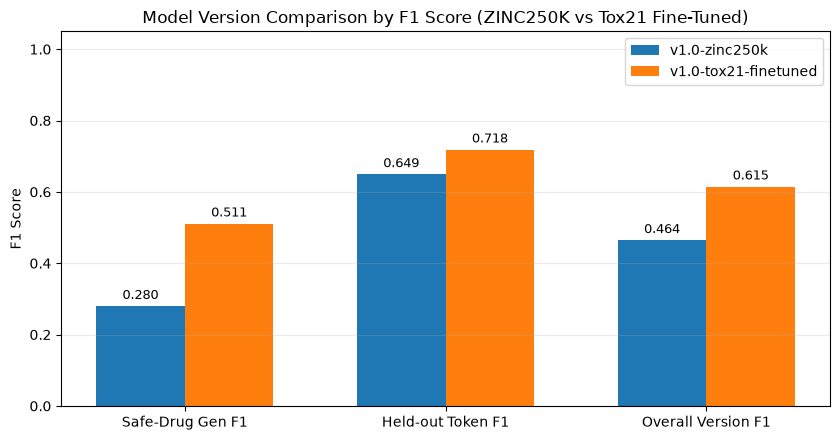

Saved version F1 leaderboard -> metrics/version_leaderboard.json
Saved F1 comparison plot     -> metrics/v1_f1_comparison.png


In [11]:
# Build fixed held-out Safe & Drug-Like reference set for generative recall
rng = np.random.default_rng(SEED)
sampled_zinc_test = rng.choice(zinc_test_smi, size=min(400, len(zinc_test_smi)), replace=False).tolist()
zinc_test_mols = [Chem.MolFromSmiles(s) for s in sampled_zinc_test]
_, zinc_test_safe_flags = score_safety_on_mols(zinc_test_mols)
safe_zinc_ref_mols = [
    m for m, is_s in zip(zinc_test_mols, zinc_test_safe_flags)
    if is_s and QED.qed(m) >= 0.5 and lipinski_passes(m)
][:150]

safe_tox_ref_mols = [Chem.MolFromSmiles(s) for s in tox_safe_test_smi]
reference_safe_mols = safe_tox_ref_mols + safe_zinc_ref_mols
reference_fps = [morgan_gen.GetFingerprint(m) for m in reference_safe_mols]
print(f"Held-out Safe Drug-Like Reference Panel: {len(reference_safe_mols)} molecules "
      f"({len(safe_tox_ref_mols)} Tox21 test + {len(safe_zinc_ref_mols)} ZINC test)")


def evaluate_checkpoint_f1(checkpoint_path: Path, n_samples: int = 1000, sim_threshold: float = 0.30) -> dict:
    model_eval, ckpt = load_generator_checkpoint(checkpoint_path, device=DEVICE)
    tok2id = ckpt["token2idx"]
    id2tok = ckpt["idx2token"]

    # 1. Held-out Safe Tox21 Token F1
    heldout_loader = DataLoader(SMILESDataset(tox_safe_test_smi, tok2id), batch_size=64, shuffle=False)
    lm_eval = evaluate_language_model(model_eval, heldout_loader)
    token_f1 = lm_eval["token_f1_weighted"]

    # 2. Sample molecules deterministically and evaluate Safe-Drug Precision & Recall
    seed_everything(SEED + 101)
    sampled_raw = model_eval.sample(num_samples=n_samples, idx2token=id2tok, temperature=0.85)

    seen_can = set()
    qualifying_safe_drug_mols = []
    valid_count = 0
    safe_count = 0
    druglike_count = 0

    cand_mols = []
    cand_smiles = []
    for smi in sampled_raw:
        if not smi:
            continue
        mol = Chem.MolFromSmiles(smi)
        if mol is None or mol.GetNumAtoms() < 4:
            continue
        valid_count += 1
        can = Chem.MolToSmiles(mol, canonical=True)
        if can in seen_can:
            continue
        seen_can.add(can)
        cand_mols.append(mol)
        cand_smiles.append(can)

    safe_probs, safe_flags = score_safety_on_mols(cand_mols, threshold=0.50)
    for mol, can, is_safe in zip(cand_mols, cand_smiles, safe_flags):
        is_dl = (QED.qed(mol) >= 0.50) and lipinski_passes(mol)
        is_novel = can not in combined_train_set
        if is_safe:
            safe_count += 1
        if is_dl:
            druglike_count += 1
        if is_safe and is_dl and is_novel:
            qualifying_safe_drug_mols.append(mol)

    # Precision: fraction of total generated samples that are Valid + Unique + Novel + Safe + Drug-Like
    gen_precision = len(qualifying_safe_drug_mols) / max(n_samples, 1)

    # Recall: fraction of held-out reference safe-drug panel covered within ECFP4 Tanimoto >= sim_threshold
    if qualifying_safe_drug_mols and reference_fps:
        gen_fps = [morgan_gen.GetFingerprint(m) for m in qualifying_safe_drug_mols]
        covered = 0
        for ref_fp in reference_fps:
            sims = DataStructs.BulkTanimotoSimilarity(ref_fp, gen_fps)
            if max(sims) >= sim_threshold:
                covered += 1
        gen_recall = covered / len(reference_fps)
    else:
        gen_recall = 0.0

    safe_drug_f1 = (
        2.0 * gen_precision * gen_recall / (gen_precision + gen_recall)
        if (gen_precision + gen_recall) > 0
        else 0.0
    )
    overall_version_f1 = 0.5 * (safe_drug_f1 + token_f1)

    return {
        "version": ckpt["version"],
        "checkpoint": str(checkpoint_path),
        "validity": valid_count / max(n_samples, 1),
        "safe_rate_unique": safe_count / max(len(cand_mols), 1),
        "druglike_rate_unique": druglike_count / max(len(cand_mols), 1),
        "gen_precision": gen_precision,
        "gen_recall": gen_recall,
        "safe_drug_gen_f1": safe_drug_f1,
        "heldout_token_f1": token_f1,
        "overall_version_f1": overall_version_f1,
    }


f1_results = [
    evaluate_checkpoint_f1(ZINC_MODEL_FILE, n_samples=1000),
    evaluate_checkpoint_f1(TOX21_MODEL_FILE, n_samples=1000),
]

f1_df = pd.DataFrame(f1_results).sort_values("overall_version_f1", ascending=False).reset_index(drop=True)
best_row = f1_df.iloc[0]

print("==================================================================")
print("         MODEL VERSION LEADERBOARD (RANKED BY F1 SCORE)           ")
print("==================================================================")
display(f1_df.style.format({
    "validity": "{:.4f}",
    "safe_rate_unique": "{:.4f}",
    "druglike_rate_unique": "{:.4f}",
    "gen_precision": "{:.4f}",
    "gen_recall": "{:.4f}",
    "safe_drug_gen_f1": "{:.4f}",
    "heldout_token_f1": "{:.4f}",
    "overall_version_f1": "{:.4f}",
}))
print(
    f"BEST VERSION -> {best_row['version']} ({best_row['checkpoint']}) | "
    f"Safe-Drug Gen F1 = {best_row['safe_drug_gen_f1']:.4f} | "
    f"Token F1 = {best_row['heldout_token_f1']:.4f} | "
    f"Overall Version F1 = {best_row['overall_version_f1']:.4f}"
)

# Persist F1 leaderboard JSON + plot for Git version tracking
LEADERBOARD_PATH = METRICS_DIR / "version_leaderboard.json"
existing_entries = []
if LEADERBOARD_PATH.exists():
    raw_lb = json.loads(LEADERBOARD_PATH.read_text())
    existing_entries = raw_lb.get("versions", []) if isinstance(raw_lb, dict) else raw_lb

by_version = {entry["version"]: entry for entry in existing_entries}
for row in f1_results:
    by_version[row["version"]] = row

sorted_leaderboard = sorted(by_version.values(), key=lambda x: x["overall_version_f1"], reverse=True)
LEADERBOARD_PATH.write_text(json.dumps({
    "best_version": sorted_leaderboard[0]["version"],
    "best_checkpoint": sorted_leaderboard[0]["checkpoint"],
    "best_overall_f1": round(sorted_leaderboard[0]["overall_version_f1"], 6),
    "versions": sorted_leaderboard,
}, indent=2) + "\n")

fig, ax = plt.subplots(figsize=(8.5, 4.5))
metrics_to_plot = ["safe_drug_gen_f1", "heldout_token_f1", "overall_version_f1"]
labels = ["Safe-Drug Gen F1", "Held-out Token F1", "Overall Version F1"]
x = np.arange(len(metrics_to_plot))
width = 0.34

for idx, row in enumerate(f1_results):
    vals = [row[m] for m in metrics_to_plot]
    bars = ax.bar(x + (idx - 0.5) * width, vals, width, label=row["version"])
    ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0, 1.05)
ax.set_ylabel("F1 Score")
ax.set_title("Model Version Comparison by F1 Score (ZINC250K vs Tox21 Fine-Tuned)")
ax.legend()
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
PLOT_PATH = METRICS_DIR / "v1_f1_comparison.png"
plt.savefig(PLOT_PATH, dpi=150)
plt.show()
print(f"Saved version F1 leaderboard -> {LEADERBOARD_PATH}")
print(f"Saved F1 comparison plot     -> {PLOT_PATH}")
